## Implementing a RNN for Review Classification using IMDB Dataset Compare simple RNN

##### Importing Libraries and Loading the Dataset
First, we need to import the necessary libraries and load the IMDB dataset. The IMDB dataset is a collection of 50,000 movie reviews, which are labeled as either positive or negative. We’ll use this dataset to train our model.

In [ ]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
# # Ensure a Single OpenMP Runtime. As a temporary workaround, you can set the environment variable KMP_DUPLICATE_LIB_OK to TRUE

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
import matplotlib.pyplot as plt

# Set random seed for reproducibility
#np.random.seed(7)
#tf.random.set_seed(7)

# Load the IMDB dataset
max_features = 10000  # Number of words to consider as features
maxlen = 500  # Cut texts after this number of words (among top max_features most common words)
batch_size = 32

(input_train, y_train), (input_test, y_test) = imdb.load_data(num_words=max_features)

# Pad sequences to ensure uniform input size
input_train = sequence.pad_sequences(input_train, maxlen=maxlen)
input_test = sequence.pad_sequences(input_test, maxlen=maxlen)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


- np.random.seed(7) and tf.random.set_seed(7): Setting the random seed ensures that the results are reproducible.
- imdb.load_data(num_words=max_features): Loads the IMDB dataset, keeping only the top max_features most frequently occurring words.
- sequence.pad_sequences: Pads the sequences to ensure they all have the same length (maxlen), which is necessary for batch processing.


#### Building and Training the Simple RNN Model
- Embedding(max_features, 32): The Embedding layer converts integer sequences into dense vectors of fixed size (32 in this case).
- SimpleRNN(32): Adds a simple RNN layer with 32 units.
- Dense(1, activation='sigmoid'): Adds a dense layer with a sigmoid activation function to output a probability (since this is a binary classification problem).
- model.compile: Configures the model for training. We use the RMSprop optimizer and binary cross-entropy loss function.
- model.fit: Trains the model for 10 epochs with a batch size of 32, using 20% of the training data for validation.

In [ ]:
# Build the model
model = Sequential()
model.add(Embedding(max_features, 32))
model.add(SimpleRNN(32))
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(input_train, y_train, epochs=10, batch_size=batch_size, validation_split=0.2)


Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 50s 67ms/step - accuracy: 0.6200 - loss: 0.6254 - val_accuracy: 0.7832 - val_loss: 0.4791
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 44ms/step - accuracy: 0.8412 - loss: 0.3816 - val_accuracy: 0.7948 - val_loss: 0.4751
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 34s 55ms/step - accuracy: 0.8744 - loss: 0.3073 - val_accuracy: 0.8438 - val_loss: 0.3695
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 31s 50ms/step - accuracy: 0.9014 - loss: 0.2542 - val_accuracy: 0.8556 - val_loss: 0.3650
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 39s 47ms/step - accuracy: 0.9260 - loss: 0.1981 - val_accuracy: 0.8450 - val_loss: 0.3977
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 29s 46ms/step - accuracy: 0.9445 - loss: 0.1511 - val_accuracy: 0.8372 - val_loss: 0.4755
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 60ms/step - accuracy: 0.9604 - loss: 0.1145 - val_accuracy: 0.8186 - val_loss: 0.4495
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 29s 46ms/step - accuracy: 0.9671 - loss: 0.0924 - 

##### Evaluating the Simple RNN Model
- model.evaluate: Evaluates the model on the test data and returns the loss and accuracy.

In [ ]:
# Evaluate the model
test_loss, test_acc = model.evaluate(input_test, y_test)
print(f'Test Accuracy: {test_acc:.2f}')

782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7841 - loss: 0.6571
Test Accuracy: 0.79


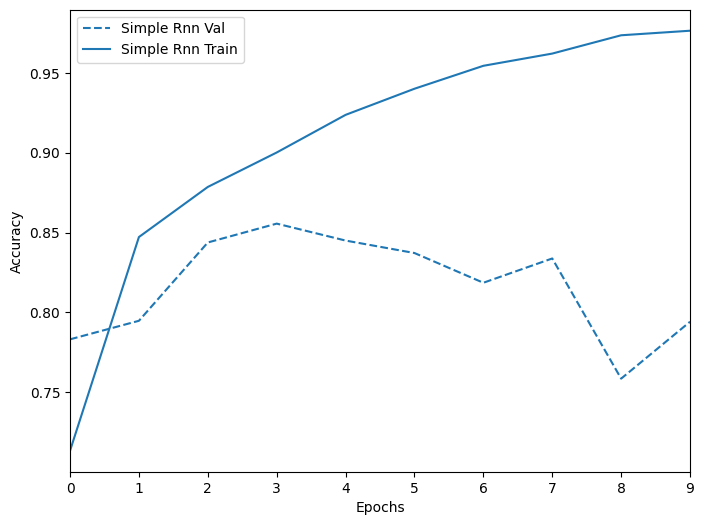

In [ ]:
# Function to plot training history
def plot_history(histories, key='accuracy'):
    plt.figure(figsize=(8,6))

    for name, history in histories:
        val = plt.plot(history.epoch, history.history['val_'+key], '--', label=name.title()+' Val')
        plt.plot(history.epoch, history.history[key], color=val[0].get_color(), label=name.title()+' Train')

    plt.xlabel('Epochs')
    plt.ylabel(key.replace('_',' ').title())
    plt.legend()
    plt.xlim([0,max(history.epoch)])
    plt.show()

# Plot the accuracy and loss for each model
plot_history([('Simple RNN', history)])

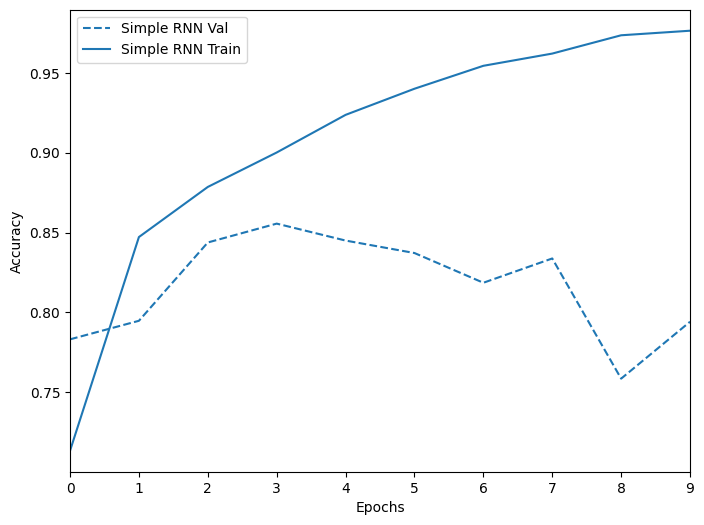

In [ ]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(8, 6))

# Plot validation accuracy (dashed line)
val = plt.plot(history.epoch, history.history['val_accuracy'], '--', label='Simple RNN Val')

# Plot training accuracy (solid line with same color)
plt.plot(history.epoch, history.history['accuracy'], color=val[0].get_color(), label='Simple RNN Train')

# Add labels, legend, and axis limits
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.xlim([0, max(history.epoch)])
plt.show()
